# Comparing the xG models


**Benchmarks:** Understat's own xG is used as a benchmark. It was kept out of every model as an input, so it is a fair reference rather than something the models copied. A constant baseline, which gives every shot the same probability (the goal rate in the training seasons), shows what a model with no shot knowledge quality would score.

**How we compare:** Goals are only about 11% of shots, so a model that always predicts "no goal" would be right about 89% of the time. Accuracy therefore says almost nothing about an xG model, and we score the probabilities themselves instead: the Brier score and log loss measure how close the probabilities are to what happened, ROC-AUC measures how well shots are ranked, and calibration plots check whether shots given an xG of, say, 0.20 really score about 20% of the time. We also compare summed xG with actual goals for each team and for the season.

| Model | Language | Method | Tuning | Final model trained on |
|---|---|---|---|---|
| Random forest | Python | scikit-learn `RandomForestClassifier` | Leave-one-season-out cross-validation | 2021/22–2024/25 |
| Gradient boosting | Python | XGBoost | Grid search, validated on 2024/25 | 2021/22–2024/25 |
| Logistic regression | Python | scikit-learn `LogisticRegression` | None; validated on 2024/25 |2021/22–2024/25 |
| Neural network | R | `nnet`, one hidden layer, average of 5 networks | Grid over hidden units and weight decay, validated on 2024/25 | 2021/22–2024/25 |

## 1. Loading the predictions

Each model's notebook exported a file with its xG for every shot in the 2025/26 test season. Each shot has a `row_id` (its row number in the cleaned Understat data), so we load the files and join them on `row_id` into one table: one row per shot, with the shot's details and a column for each model's xG. Understat's xG and the actual outcome (`goal`) are included for comparison.

To make sure every file describes the same shots, we check that the outcome and Understat's xG agree for every shot across all four files. If any file were misaligned, these checks would stop the notebook instead of silently pairing predictions with the wrong shots.

In [1]:
import pandas as pd
import numpy as np

# Folder holding the four prediction files, read straight from our GitHub repo:
# https://github.com/donny31415/Group-Sprint-1/tree/main/results
BASE_URL = "https://raw.githubusercontent.com/donny31415/Group-Sprint-1/main/results/"

files = {
    "rf_xg": "rf_xg_predictions_2025_26.csv",
    "lr_xg": "lr_xg_predictions_2025_26.csv",
    "nn_xg": "nn_xg_predictions_2025_26.csv",
    "gb_xg": "gb_xg_predictions_2025_26.csv",
}

def load_csv(filename):
    """Read one prediction file from the repo, failing with a clear message if it cannot be found."""
    url = BASE_URL + filename
    try:
        return pd.read_csv(url)
    except Exception as e:
        raise FileNotFoundError(f"Cannot load {url} ({e})") from e

# Shot details, taken from the random forest file
first = load_csv(files["rf_xg"])
shots = first[["row_id", "season", "team", "is_penalty", "goal", "understat_xg"]]
n_shots = len(shots)

# Add each model's xG, matched by row_id
for col, filename in files.items():
    model = load_csv(filename)

    shots = shots.merge(model[["row_id", col, "goal", "understat_xg"]],
                        on="row_id", suffixes=("", "_check"), validate="one_to_one")

    # The merge is an inner join, so check no shots were silently dropped
    assert len(shots) == n_shots, f"{filename}: row_ids do not line up ({len(shots)} of {n_shots} matched)"

    # Check this file describes the same shots: outcomes and Understat xG must match
    assert (shots["goal"] == shots["goal_check"]).all(), f"{filename}: goals do not match"
    assert np.allclose(shots["understat_xg"], shots["understat_xg_check"]), \
        f"{filename}: Understat xG does not match"
    shots = shots.drop(columns=["goal_check", "understat_xg_check"])

print(len(shots), "shots")   # should be 9483
shots.head()

9483 shots


,row_id,season,team,is_penalty,goal,understat_xg,rf_xg,lr_xg,nn_xg,gb_xg
0,39657,2025/26,Liverpool,0,0,0.014601,0.021962,0.021639,0.022688,0.014495
1,39658,2025/26,Liverpool,0,0,0.042656,0.036348,0.046737,0.044787,0.033833
2,39659,2025/26,Liverpool,0,0,0.257975,0.164594,0.091436,0.105742,0.139872
3,39660,2025/26,Liverpool,0,0,0.077662,0.063644,0.074960,0.085178,0.074286
4,39661,2025/26,Liverpool,0,1,0.404091,0.221226,0.263852,0.334847,0.342524


## 2. Headline scores

We score every model on the same 9,483 shots, alongside Understat's xG and a constant baseline that gives every shot the same probability (the goal rate in the training seasons, 0.1097). For each shot $i$, $p_i$ is the predicted xG and $y_i$ is 1 for a goal and 0 otherwise. Note that we use the Brier and log loss formula given in 01_Introduction.ipynb.

- **Brier score**: the average squared gap between the predicted probability and what happened. Lower is better.
- **Log loss**: like the Brier score, but it punishes confident mistakes much more heavily, such as giving 0.01 to a shot that goes in. Lower is better.
- **ROC-AUC**: the probability that a randomly chosen goal was given a higher xG than a randomly chosen non-goal. It measures how well shots are ranked, but not whether the probabilities themselves are right. Higher is better, and 0.5 means no better than chance.
- **Accuracy**: the share of shots classified correctly if every shot with xG above 0.5 is called a goal. It is included only to show why it is unsuitable for xG.

In [2]:
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

# Constant baseline
TRAIN_GOAL_RATE = 0.1097
shots["constant_xg"] = TRAIN_GOAL_RATE

models = {
    "Random forest": "rf_xg",
    "Gradient boosting": "gb_xg",
    "Logistic regression": "lr_xg",
    "Neural network": "nn_xg",
    "Understat xG": "understat_xg",
    "Constant baseline": "constant_xg",
}
# Only keep models whose files have been loaded
models = {name: col for name, col in models.items() if col in shots.columns}

rows = []
for name, col in models.items():
    p = shots[col]
    rows.append({
        "Model": name,
        "Brier score": brier_score_loss(shots["goal"], p),
        "Log loss": log_loss(shots["goal"], p),
        "ROC-AUC": roc_auc_score(shots["goal"], p),
        "Accuracy (0.5 cut-off)": ((p > 0.5) == shots["goal"]).mean(),
    })

scores = pd.DataFrame(rows).set_index("Model").sort_values("Brier score")
scores.round(4)

,Brier score,Log loss,ROC-AUC,Accuracy (0.5 cut-off)
Model,,,,
Understat xG,0.0756,0.2671,0.8014,0.8994
Neural network,0.0783,0.2770,0.7809,0.9033
Gradient boosting,0.0785,0.2787,0.7763,0.9048
Random forest,0.0789,0.2790,0.7773,0.9044
Logistic regression,0.0791,0.2819,0.7718,0.9038
Constant baseline,0.0947,0.3379,0.5000,0.8941


## 3. Calibration

A model is well calibrated if its probabilities mean what they say, i.e of all the shots given an xG of about 0.2, roughly 20% should be scored. The Brier score and log loss mix calibration with how well a model separates good chances from poor ones so we check calibration separately.

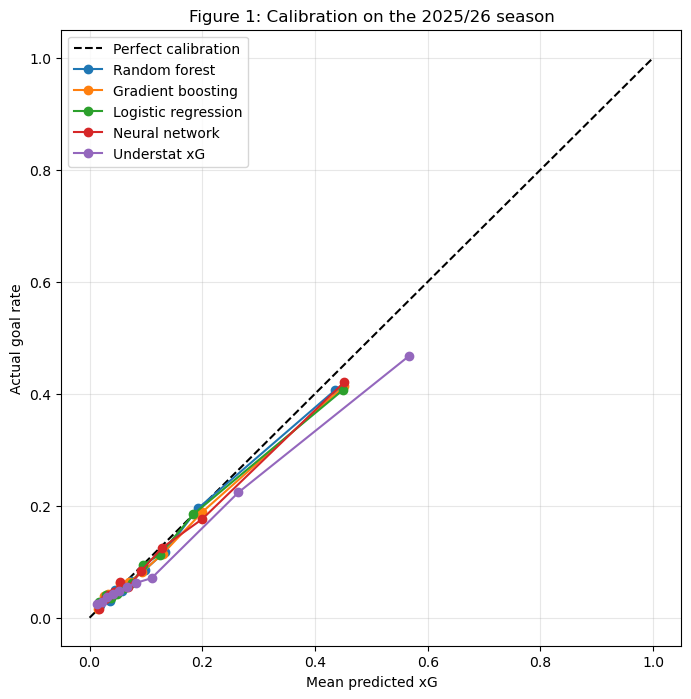

In [3]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")

for name, col in models.items():
    if col == "constant_xg":
        continue
    actual, predicted = calibration_curve(shots["goal"], shots[col], n_bins=10, strategy="quantile")
    plt.plot(predicted, actual, marker="o", label=name)

plt.xlabel("Mean predicted xG")
plt.ylabel("Actual goal rate")
plt.title("Figure 1: Calibration on the 2025/26 season")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Figure 1 groups each model's shots into ten bins of equal size, ordered by predicted xG, and plots the average predicted xG in each bin against the share of those shots that were actually scored. A perfectly calibrated model lies on the dashed diagonal. Points above it mean the model is too pessimistic (more goals than predicted), and points below it mean it is too optimistic. Generally, all four of our models are more optimistic than pessimistic but Understat xG is the most optimistic. Note that the constant baseline is left out because it gives every shot the same value so it would be a single point.

The table below gives the same comparison in fixed xG bands, which makes it easier to read off the larger chances.

In [4]:
bands = [0, 0.05, 0.1, 0.2, 0.3, 0.5, 1]

tables = []
for name, col in models.items():
    if col == "constant_xg":
        continue
    band = pd.cut(shots[col], bands).rename("xG band")
    t = shots.groupby(band, observed=True).agg(predicted=(col, "mean"), actual=("goal", "mean"))
    t.columns = pd.MultiIndex.from_product([[name], t.columns])
    tables.append(t)

calibration_table = pd.concat(tables, axis=1)
calibration_table.round(3)

Random forest        Gradient boosting        Logistic regression  \
                predicted actual         predicted actual           predicted   
xG band                                                                         
(0.0, 0.05]         0.032  0.034             0.030  0.036               0.031   
(0.05, 0.1]         0.071  0.065             0.071  0.070               0.072   
(0.1, 0.2]          0.143  0.134             0.141  0.122               0.137   
(0.2, 0.3]          0.245  0.236             0.245  0.227               0.243   
(0.3, 0.5]          0.383  0.317             0.383  0.333               0.384   
(0.5, 1.0]          0.698  0.700             0.705  0.689               0.710   

                   Neural network        Understat xG         
            actual      predicted actual    predicted actual  
xG band                                                       
(0.0, 0.05]  0.034          0.031  0.035        0.028  0.034  
(0.05, 0.1]  0.063          0.070  0.063        0.071  0.058  
(0.1, 0.2]   0.135          0.139  0.127        0.125  0.078  
(0.2, 0.3]   0.224          0.245  0.242        0.263  0.203  
(0.3, 0.5]   0.345          0.375  0.341        0.394  0.335  
(0.5, 1.0]   0.653          0.702  0.659        0.648  0.544

## 4. Season and team totals

xG is often used to judge teams over a season, by comparing the goals a team was expected to score with the goals it actually scored. We therefore add up each model's xG across the 2025/26 season for each team and compare the totals with actual goals.

Totals and per shot scores test different things. When predictions are added up, a model that is too high on some shots and too low on others can still reach the right total because the errors cancel out. Hence a total checks whether a model's overall level is right but not whether it gives each shot a sensible probability. The constant baseline is included to show this. It knows nothing about shot quality yet its totals can still look reasonable.

In [5]:
team_totals = shots.groupby("team").agg(
    shots=("goal", "size"),
    goals=("goal", "sum"),
    **{name: (col, "sum") for name, col in models.items()},
).sort_values("goals", ascending=False)

team_totals.round(1)

,shots,goals,Random forest,Gradient boosting,Logistic regression,Neural network,Understat xG,Constant baseline
team,,,,,,,,
Manchester City,593,74,72.1,73.5,73.3,74.7,81.2,65.1
Arsenal,552,66,69.2,70.1,71.3,71.0,79.0,60.6
Manchester United,596,66,66.4,66.9,66.0,66.5,74.2,65.4
Liverpool,584,61,58.6,58.7,59.5,59.1,67.8,64.1
Bournemouth,525,57,61.8,62.9,63.6,61.9,68.7,57.6
Chelsea,509,57,64.5,64.9,65.8,66.0,73.5,55.8
Aston Villa,482,53,49.6,49.5,50.8,49.1,58.5,52.9
Brentford,406,53,56.2,55.3,54.4,55.0,66.6,44.5
Newcastle United,492,53,56.5,56.8,57.9,57.1,63.1,54.0


In [6]:
actual_goals = shots["goal"].sum()

rows = []
for name, col in models.items():
    total = shots[col].sum()
    rows.append({
        "Model": name,
        "Total xG": total,
        "Season error (%)": 100 * (total - actual_goals) / actual_goals,
        "Mean team error (goals)": (team_totals[name] - team_totals["goals"]).abs().mean(),
    })

totals_summary = pd.DataFrame(rows).set_index("Model")

print("Actual goals in 2025/26:", int(actual_goals))
totals_summary.round(1)

Actual goals in 2025/26: 1004


,Total xG,Season error (%),Mean team error (goals)
Model,,,
Random forest,1063.4,5.9,4.4
Gradient boosting,1053.9,5.0,4.0
Logistic regression,1066.2,6.2,4.2
Neural network,1057.3,5.3,4.0
Understat xG,1183.9,17.9,9.0
Constant baseline,1040.3,3.6,4.3


## 5. Is the best model truly best?

The models' Brier scores differ only in the third or fourth decimal place so we need to check whether those gaps are real or could have arisen by chance from the particular shots in one season.

In [7]:
import numpy as np

B = 1000                                  # number of bootstrap resamples
rng = np.random.default_rng(42)

# Squared error for every shot and model (the Brier score is the mean of these)
errors = pd.DataFrame({name: (shots[col] - shots["goal"]) ** 2 for name, col in models.items()})

# Reference: the best of our four models by Brier score (from section 2)
group_models = [m for m in ["Random forest", "Gradient boosting", "Logistic regression", "Neural network"] if m in models]
reference = scores.loc[group_models, "Brier score"].idxmin()

# Resample shots and recompute every model's Brier score on the same resample
E = errors.to_numpy()
n = len(E)
boot = np.empty((B, E.shape[1]))
for b in range(B):
    idx = rng.integers(0, n, n)
    boot[b] = E[idx].mean(axis=0)
boot = pd.DataFrame(boot, columns=errors.columns)

# Difference from the reference in each resample (positive = worse than the reference)
diff = boot.sub(boot[reference], axis=0)

rows = []
for name in errors.columns:
    if name == reference:
        continue
    low, high = np.percentile(diff[name], [2.5, 97.5])
    rows.append({
        "Model": name,
        "Brier difference": errors[name].mean() - errors[reference].mean(),
        "95% CI low": low,
        "95% CI high": high,
        "Worse than reference in (% of resamples)": 100 * (diff[name] > 0).mean(),
    })

bootstrap_table = pd.DataFrame(rows).set_index("Model")
print("Reference model:", reference)
bootstrap_table.round(4)

Reference model: Neural network


,Brier difference,95% CI low,95% CI high,Worse than reference in (% of resamples)
Model,,,,
Random forest,0.0005,-0.0000,0.0011,97.1
Gradient boosting,0.0002,-0.0003,0.0007,74.6
Logistic regression,0.0008,0.0002,0.0012,99.8
Understat xG,-0.0027,-0.0043,-0.0011,0.0
Constant baseline,0.0164,0.0136,0.0189,100.0


## Interpretation of the table

We use a **paired bootstrap** on the Brier score. In each of 1,000 resamples we draw 9,483 shots from the 2025/26 test set with replacement (the same size as the test set) and compute every model's Brier score on that same resample. Pairing matters because the models are scored on identical shots, so shot difficulty cancels out and the difference between two models is estimated much more precisely than either score alone. The reference is the best of our four models by Brier score, the neural network. For each other model we report the difference in Brier score from the reference (positive means worse), a 95% percentile interval for that difference, and the percentage of resamples in which the model scored worse. If the interval excludes 0, the gap is unlikely to be explained by which shots happened to fall in this season. Note that the last column is a measure of consistency, not a p-value.

**Results**

- **Understat xG** is the only model that beats the neural network: its difference of -0.0027 (95% CI -0.0043 to -0.0011) excludes 0, and it was never worse than the reference. Understat is a benchmark rather than a competitor, since the group did not train it, so this shows how much room remains rather than a model we could have chosen.
- **Logistic regression** is consistently but only slightly worse than the neural network (difference 0.0008, 95% CI 0.0002 to 0.0012, worse in 99.8% of resamples). This gap is about 5% of the 0.0164 gap between the neural network and the constant baseline, so it is reliable but small.
- **Random forest** is borderline: its difference of 0.0005 has an interval that only just includes 0 (lower bound -0.0000 to four decimal places) and it was worse in 97.1% of resamples. We therefore treat it as probably, but not demonstrably, worse.
- **Gradient boosting** cannot be separated from the neural network: its difference is 0.0002, its interval (-0.0003 to 0.0007) spans 0, and it was worse in only 74.6% of resamples.
- **Constant baseline** is worse than every model in all resamples (difference 0.0164, 95% CI 0.0136 to 0.0189). Hence every model carries real predictive information beyond the average goal rate, and the differences among our four models are small by comparison.

**Analysis:** The neural network has the lowest Brier score of the four models we built, but its lead is at most 0.0008, and only the gap to the logistic regression is clearly separated from 0. The neural network is therefore best on the point estimates rather than decisively, and gradient boosting (and, more tentatively, the random forest) cannot be ruled out as equally good. Because the Brier differences are so small, the final choice should rest on more than this one metric: Section 3 shows that our models are better calibrated than Understat, Section 2 shows the same ranking on log loss and a slightly different one on ROC-AUC, and Section 4 shows that totals are sensitive to calibration rather than ranking. Interpretability also matters for the finishing analysis. The logistic regression is the only model whose effects can be read directly (see the odds ratios in the full model notebook), and it gives up very little accuracy for this.

**Limitations**

- **Dependence between shots:** The resampling unit is the individual shot, which ignores clustering within matches, teams and players. The intervals are therefore probably too narrow, and a cluster bootstrap resampling whole matches would be more defensible (it needs a match identifier, which is not in the exported prediction files).
- **Multiple comparisons:** Five comparisons are made at the 95% level without adjustment, so the logistic regression result (lower bound 0.0002) should be treated with caution, and the random forest result sits on the boundary.
- **Reference-only comparisons:** Every difference is relative to the neural network, so two non-reference models (for example the logistic regression and the random forest) have not been compared directly. Because the resamples are shared, this could be done at no extra cost.
- **One metric, one season:** Only the Brier score on a single test season is bootstrapped. Log loss, ROC-AUC or the error in team-level total xG, which the finishing analysis depends on, could rank the models differently. The bootstrap also captures sampling variation in the test shots but not variation from retraining the models.

## 6. Conclusions and limitations

### Conclusions

**Quality of the probabilities:** On the 2025/26 season, all four models are far better than the constant baseline (Brier scores of 0.0783 to 0.0791 against 0.0947, and log losses of 0.277 to 0.282 against 0.338), and all four fall short of Understat's xG (0.0756 and 0.2671). Among our models, the neural network scores best on Brier score, log loss and ROC-AUC (0.0783, 0.2770 and 0.781), followed by gradient boosting, the random forest and logistic regression. The Brier score and log loss rank the four models in the same order. ROC-AUC swaps gradient boosting and the random forest.

**Why the models performed the way they did:** Every model beats the constant baseline by a wide margin, so shot location and shot type carry most of the useful information, and all four algorithms are able to find it. The three flexible models (neural network, gradient boosting and random forest) are slightly ahead of the logistic regression, which is the most restricted of the four because its log-odds are a fixed combination of the features it is given. A plausible explanation is that the flexible models capture some non-linear effects and interactions that the logistic regression misses, but note that this was not tested directly and the gaps are small. That the four models finish so close together suggests that most of the signal in these features is simple in form. Understat's better separation is likely to come from information that our data does not contain (see the limitations below).

**Is the best truly best?** The gaps between our models are small, and the bootstrap in section 5 shows that only some of them are reliable. Logistic regression is clearly worse than the neural network (95% interval for the difference in Brier score: 0.0002 to 0.0012). The random forest is worse in 97.1% of resamples, but its interval only just includes zero, so the evidence is borderline. Gradient boosting cannot be distinguished from the neural network (it is worse in only 74.6% of resamples, with an interval of -0.0003 to 0.0007). Understat is clearly better than all four (difference -0.0027, interval -0.0043 to -0.0011). The neural network and gradient boosting are therefore joint best of our models on this season, the random forest is not clearly worse, and no model closes the gap to Understat.

**Calibration versus separation:** Our four models are better calibrated than Understat. Their predicted xG is close to the actual goal rate in most bands, apart from a mild over-prediction for chances rated 0.3 to 0.5. Understat's xG is too high in almost every band: shots it rates between 0.1 and 0.2 average a predicted 0.125 but were scored only 7.8% of the time. Even so, Understat has the better Brier score, log loss and ROC-AUC, because it separates good chances from poor ones more sharply. Both the Brier score and log loss reward calibration and separation together, and here Understat's better separation outweighs its worse calibration. Which model is "best" therefore depends on the use: for ranking chances Understat is better, while for probabilities that can be taken at face value our models are better.

**Totals:** Understat's over-prediction carries through to the totals. Its xG adds up to 1,184 against 1,004 actual goals (17.9% too high), and it is off by 9.0 goals per team on average. Our models are 5 to 6% too high and off by 4.0 to 4.4 goals per team. However, the constant baseline is the closest of all on the season total (3.6% too high) and is only slightly behind our models on team totals (4.3 goals against 4.0 to 4.4), despite knowing nothing about shot quality. This is largely because a team's total depends mainly on how many shots it takes. Totals check whether a model's overall level is right, but not whether it rates each shot sensibly. Hence, judged on totals alone, the constant baseline would look like one of the best models.

**Accuracy:** Accuracy with a 0.5 cut-off lies between 0.894 and 0.905 for every model, including the constant baseline, and it ranks Understat (0.899) below all four of our models, the opposite of every probability-based measure. Note that the constant baseline already scores 0.894, the share of shots that are not goals. This confirms that accuracy is unsuitable for judging xG.

**Choice of model:** The neural network has the best point estimates, but its lead over gradient boosting and the random forest is not reliable, and the differences between all four are small compared with the gap to the constant baseline. Hence the finishing analysis can reasonably use the neural network, and it is worth repeating the key results with another model, such as the logistic regression, to check that the conclusions do not depend on this choice. The logistic regression has the advantage that its effects can be read directly.

### Limitations

- **One test season.** The comparison uses 9,483 shots and 1,004 goals from a single season. The rankings, especially the close ones, could differ in another season.
- **Independent shots assumed.** The bootstrap treats shots as independent, although shots from the same match are related, so the intervals may be somewhat too narrow. Borderline results, such as the random forest's, should be read with caution.
- **Models were not built identically.** Tuning differed (leave-one-season-out cross-validation, a single validation season, or no tuning), and so did the features: gradient boosting and the neural network add a distance-to-goal feature, and logistic regression replaces the raw coordinates with distance and offset features. The differences between models therefore reflect each whole pipeline, not just the choice of algorithm.
- **Shared data limits.** No model has goalkeeper or defender positions, or any information about how the shot was struck, which is likely part of why all four fall short of Understat. That four quite different models score so similarly suggests that the available information, rather than the choice of algorithm, sets the limit on performance. Note that the differences in features above mean this cannot be separated cleanly from the effect of the algorithm.
- **Understat is a benchmark, not the truth.** Its xG uses information we do not have, and we do not know exactly how it is calculated, so beating or matching it is not the same as being correct.